# Module 13 — Beta-VAE

Explore how weighting KL regularization changes a VAE's reconstruction and latent representation. We use the same MNIST model and data pipeline as `01_VAE.ipynb`; the defining change is the objective, not the architecture.

**Objective:** `L = reconstruction_loss + beta * KL(q(z|x) || N(0, I))`. Beta-VAE can encourage more constrained representations, but a larger beta does not guarantee disentanglement.

## What to look for

- `beta < 1`: weaker regularization may preserve more input detail, while posterior codes can move farther from the prior.
- `beta = 1`: standard VAE objective.
- `beta > 1`: stronger regularization may constrain the code, and can reduce reconstruction quality or make dimensions inactive.

These are tendencies, not guarantees. Outcomes depend on the dataset, capacity, latent size, likelihood, and loss scaling. A factorized prior does not identify semantic factors by itself.

In [1]:
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [2]:
transform = transforms.ToTensor()
train_data = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)
len(train_data), len(test_data)

(60000, 10000)

## Model and beta-weighted loss

The encoder predicts `mu` and `log_var`; reparameterization enables gradient-based training through sampling. Reconstruction BCE and KL are each summed over their features and averaged over the batch. Keep this reduction fixed when comparing beta values: beta's effective scale depends on the loss conventions.

In [3]:
class VAE(nn.Module):
    def __init__(self, latent_dim=20):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.ReLU())
        self.fc_mu = nn.Linear(400, latent_dim)
        self.fc_log_var = nn.Linear(400, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 400), nn.ReLU(),
            nn.Linear(400, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.encoder(x.flatten(start_dim=1))
        return self.fc_mu(h), self.fc_log_var(h)

    def reparameterize(self, mu, log_var):
        return mu + torch.exp(0.5 * log_var) * torch.randn_like(mu)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, log_var = self.encode(x)
        return self.decode(self.reparameterize(mu, log_var)), mu, log_var

def loss_terms(reconstruction, x, mu, log_var):
    recon = F.binary_cross_entropy(reconstruction, x, reduction='none').flatten(1).sum(1).mean()
    kl_per_dim = -0.5 * (1 + log_var - mu.square() - log_var.exp()).mean(0)
    return recon, kl_per_dim.sum(), kl_per_dim

In [4]:
def run_epoch(model, loader, beta, optimizer=None):
    training = optimizer is not None
    model.train(training)
    totals = torch.zeros(3)
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for x, _ in loader:
            x = x.to(device)
            if training:
                optimizer.zero_grad()
            reconstruction, mu, log_var = model(x)
            recon, kl, _ = loss_terms(reconstruction, x, mu, log_var)
            loss = recon + beta * kl
            if training:
                loss.backward()
                optimizer.step()
            totals += torch.tensor([loss.item(), recon.item(), kl.item()]) * x.size(0)
    return (totals / len(loader.dataset)).tolist()

# Use a compact sweep for a clear comparison. Increase epochs for better samples.
betas = [0.5, 1.0, 4.0]
epochs = 20
models, histories = {}, {}
for beta in betas:
    torch.manual_seed(42)  # Same initialization for a fairer starting point
    model = VAE(latent_dim=20).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = {'train': [], 'test': []}
    for epoch in range(epochs):
        history['train'].append(run_epoch(model, train_loader, beta, optimizer))
        history['test'].append(run_epoch(model, test_loader, beta))
    models[beta], histories[beta] = model, history
    metrics = history['test'][-1]
    print(f'beta={beta:g}: test total/recon/KL = {metrics[0]:.1f} / {metrics[1]:.1f} / {metrics[2]:.1f}')

beta=0.5: test total/recon/KL = 89.3 / 72.2 / 34.1
beta=1: test total/recon/KL = 103.7 / 78.6 / 25.2
beta=4: test total/recon/KL = 147.2 / 110.1 / 9.3


## Compare learning curves and reconstructions

Track reconstruction and KL separately. Total objective values across different beta settings are not directly comparable as reconstruction scores because the KL term has a different weight.

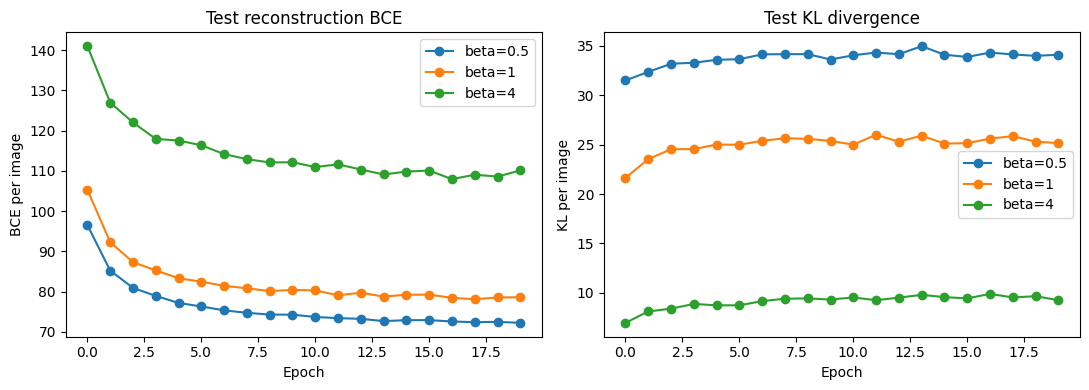

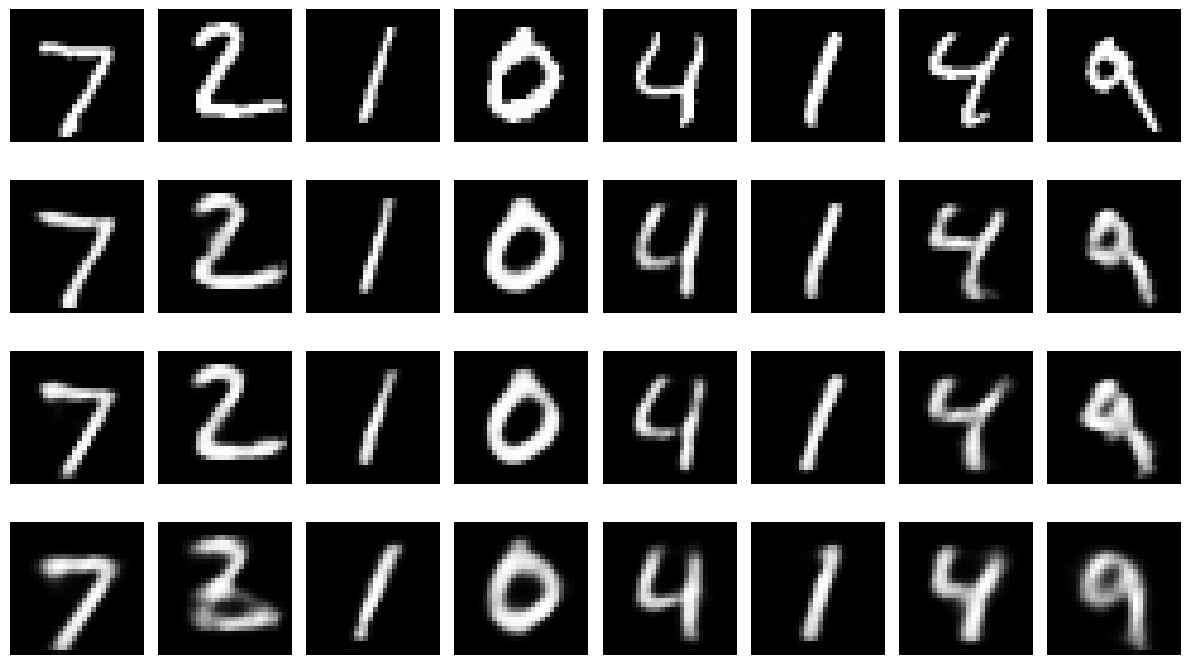

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for beta in betas:
    test = histories[beta]['test']
    axes[0].plot([row[1] for row in test], marker='o', label=f'beta={beta:g}')
    axes[1].plot([row[2] for row in test], marker='o', label=f'beta={beta:g}')
axes[0].set(title='Test reconstruction BCE', xlabel='Epoch', ylabel='BCE per image')
axes[1].set(title='Test KL divergence', xlabel='Epoch', ylabel='KL per image')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

images, _ = next(iter(test_loader))
images = images[:8].to(device)
fig, axes = plt.subplots(len(betas) + 1, 8, figsize=(12, 1.8 * (len(betas) + 1)))
for j in range(8):
    axes[0, j].imshow(images[j, 0].cpu(), cmap='gray'); axes[0, j].axis('off')
axes[0, 0].set_ylabel('Original')
for row, beta in enumerate(betas, start=1):
    model = models[beta].eval()
    with torch.no_grad(): recon, _, _ = model(images)
    for j in range(8):
        axes[row, j].imshow(recon[j, 0].cpu(), cmap='gray'); axes[row, j].axis('off')
    axes[row, 0].set_ylabel(f'beta={beta:g}')
plt.tight_layout(); plt.show()

## Inspect KL per latent dimension

A near-zero KL value for a dimension suggests it carries little information under this model. Check whether stronger regularization reduces KL broadly or leaves some dimensions active. This is a diagnostic, not a disentanglement score.

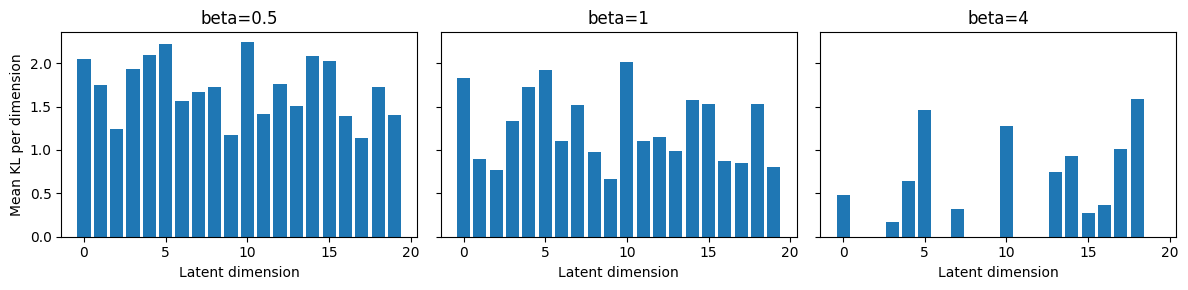

In [6]:
fig, axes = plt.subplots(1, len(betas), figsize=(12, 3), sharey=True)
for ax, beta in zip(axes, betas):
    model = models[beta].eval()
    kl_dims = torch.zeros(model.latent_dim)
    with torch.no_grad():
        for x, _ in test_loader:
            _, mu, log_var = model(x.to(device))
            kl_dims += (-0.5 * (1 + log_var - mu.square() - log_var.exp())).sum(0).cpu()
    kl_dims /= len(test_data)
    ax.bar(range(model.latent_dim), kl_dims.numpy())
    ax.set(title=f'beta={beta:g}', xlabel='Latent dimension')
axes[0].set_ylabel('Mean KL per dimension')
plt.tight_layout(); plt.show()

## Latent traversals

Encode one test digit to its mean `z`, vary one coordinate across a range, and decode. A traversal that changes one property smoothly with few side effects is suggestive of selectivity. MNIST has no labels for the underlying generative factors, so these images cannot prove disentanglement. Repeat across examples and dimensions, and treat inactive or unstable traversals as useful observations.

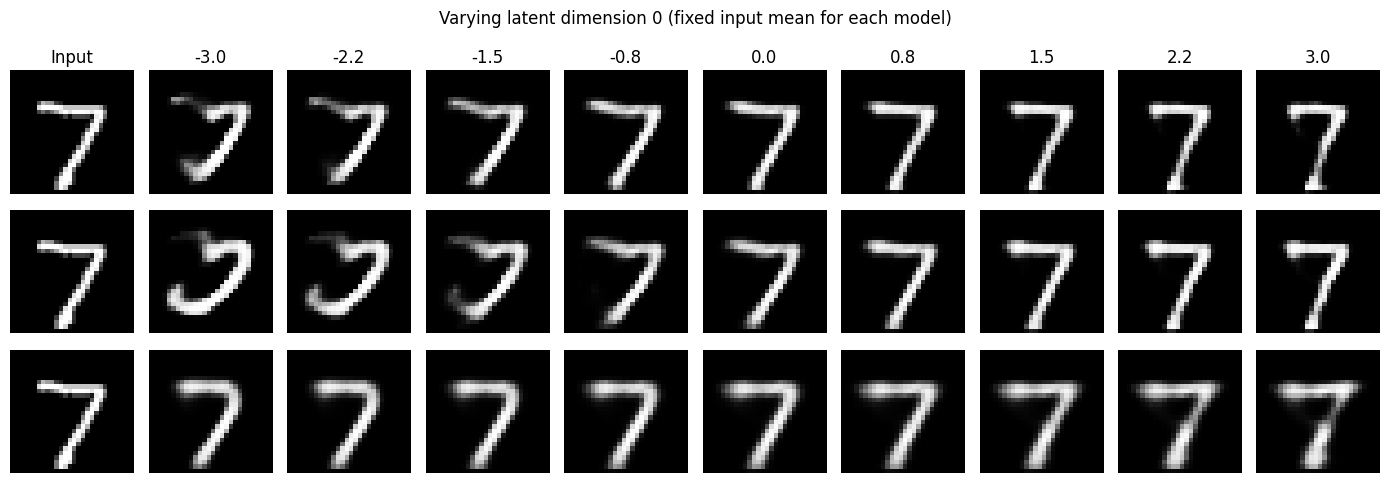

In [7]:
example = test_data[0][0].unsqueeze(0).to(device)
traversal_values = torch.linspace(-3, 3, 9)
dimension = 0  # Try other dimensions too
fig, axes = plt.subplots(len(betas), len(traversal_values) + 1, figsize=(14, 5))
for row, beta in enumerate(betas):
    model = models[beta].eval()
    with torch.no_grad(): mu, _ = model.encode(example)
    axes[row, 0].imshow(example[0, 0].cpu(), cmap='gray'); axes[row, 0].axis('off')
    axes[row, 0].set_ylabel(f'beta={beta:g}')
    z = mu.repeat(len(traversal_values), 1)
    z[:, dimension] = traversal_values.to(device)
    with torch.no_grad(): decoded = model.decode(z).cpu()
    for col, image in enumerate(decoded, start=1):
        axes[row, col].imshow(image[0], cmap='gray'); axes[row, col].axis('off')
axes[0, 0].set_title('Input')
for col, value in enumerate(traversal_values, start=1): axes[0, col].set_title(f'{value:.1f}')
plt.suptitle(f'Varying latent dimension {dimension} (fixed input mean for each model)')
plt.tight_layout(); plt.show()

## Interpretation and practical tuning

A useful experiment holds architecture, preprocessing, data split, optimizer, and evaluation protocol fixed; it changes beta and records reconstruction, KL, prior samples, and traversals. For datasets with known factors, metrics such as MIG, DCI, SAP, or FactorVAE score can support evaluation, though each has limitations and requires factor labels. No single score establishes universal interpretability or downstream usefulness.

Potential uses include controllable generation, simulation, and scientific representation analysis when the data support meaningful factors. Compare against a standard VAE and task-specific alternatives before choosing a model. Select beta for the intended balance of fidelity, sampling, and useful representation, not simply for a high disentanglement score.

## Key takeaways

- Beta-VAE changes the KL weight in the training objective.
- Larger beta constrains information in the latent code more strongly; reconstruction can suffer.
- Stronger regularization may encourage factor separation, but does not guarantee disentanglement.
- Traversals are an intuitive probe; inspect multiple inputs and dimensions.
- Unsupervised observations plus a factorized prior do not uniquely identify semantic factors.